# $\phi$ \ $\chi$ spectra
Comparing observed spectra of acoustic phase, $\phi$ and log-amplitude, $\chi$ with modelled spectra given Garrett-Munk internal waves spectra (calculated with WFT).

In [1]:
import os
import pickle
from itertools import cycle

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from dotenv import find_dotenv, load_dotenv
from scipy import signal, optimize
import colorsys
from matplotlib import lines as mlines
from matplotlib.legend_handler import HandlerBase, HandlerTuple

from n23_fluctuations_ragland import tools
import warnings
_ = load_dotenv(find_dotenv())

%config InlineBackend.figure_format = 'retina'
%load_ext autoreload
%autoreload 2

In [2]:
class HandlerTupleVertical(HandlerBase):
    """Stack the handles in a tuple vertically (offset in y) instead of
    HandlerTuple's default horizontal (x) offset."""

    def __init__(self, ndivide=1, pad=None, **kwargs):
        self._ndivide = ndivide
        self._pad = pad
        super().__init__(**kwargs)

    def create_artists(self, legend, orig_handle, xdescent, ydescent, width,
                        height, fontsize, trans):
        handler_map = legend.get_legend_handler_map()
        ndivide = len(orig_handle) if self._ndivide is None else self._ndivide
        pad = (legend.borderpad * fontsize) if self._pad is None else (self._pad * fontsize)

        if ndivide > 1:
            height = (height - pad * (ndivide - 1)) / ndivide

        yds_cycle = cycle(ydescent - (height + pad) * np.arange(ndivide))

        a_list = []
        for handle1 in orig_handle:
            handler = legend.get_legend_handler(handler_map, handle1)
            a_list.extend(handler.create_artists(
                legend, handle1, xdescent, next(yds_cycle), width, height,
                fontsize, trans))
        return a_list

## Figure setting and colors

In [3]:
# Define your colors
whoi_colors = ['#00B7BD', '#EE5340']

In [4]:
def lighten_color(hex_color, saturation_scale=0.5, lightness_scale=1.5):
    """
    Lighten a hex color similar to seaborn's tab20 palette
    
    Args:
        hex_color: Hex color string (e.g., '#1f77b4')
        saturation_scale: Multiply saturation by this (default 0.5)
        lightness_scale: Multiply lightness by this (default 1.5)
    """
    # Remove '#' if present
    hex_color = hex_color.lstrip('#')
    
    # Convert hex to RGB (0-1 range)
    r, g, b = tuple(int(hex_color[i:i+2], 16) / 255.0 for i in (0, 2, 4))
    
    # Convert RGB to HLS
    h, l, s = colorsys.rgb_to_hls(r, g, b)
    
    # Adjust saturation and lightness
    s_new = min(1.0, s * saturation_scale)
    l_new = min(1.0, l * lightness_scale)
    
    # Convert back to RGB
    r_new, g_new, b_new = colorsys.hls_to_rgb(h, l_new, s_new)
    
    # Convert to hex
    return '#{:02x}{:02x}{:02x}'.format(
        int(r_new * 255),
        int(g_new * 255),
        int(b_new * 255)
    )

In [5]:
plt.rcParams.update({"font.size": 8})
plt.rcParams["text.usetex"] = True

In [6]:
colors = [
    whoi_colors[0],
    lighten_color(whoi_colors[0], lightness_scale=2),
    whoi_colors[1],
    lighten_color(whoi_colors[1], lightness_scale=1.4, saturation_scale=1)
]

## open observations and LS fit

In [18]:
# open observations
m_data, F_phi_data, F_chi_data, F_phi_lm, F_phi_ls, F_chi_lm, F_chi_ls = tools.estimate_F_phi_chi(remove_array_tilt=True)

In [21]:
F_chi_ls

{'+7': array([1.21777156, 1.31599605, 1.33641737, 1.33503311, 1.4226355 ,
        1.37821406, 1.34704479, 1.34002323, 1.3654542 , 1.27708768,
        1.29115874, 1.29288473, 1.2872565 , 1.64442394]),
 '-7': array([1.41676218, 1.35037213, 1.23030451, 1.33980877, 1.46964285,
        1.42522449, 1.34052804, 1.27404273, 1.40705107, 1.25868589,
        1.36749861, 1.29867914, 1.29725759, 1.76437471]),
 '-6': array([1.29555182, 1.353483  , 1.2747113 , 1.34295988, 1.38579046,
        1.27803203, 1.38271767, 1.2507976 , 1.309958  , 1.27537414,
        1.28100076, 1.28837039, 1.3850368 , 1.75920291]),
 '+6': array([1.38867761, 1.33484851, 1.3333081 , 1.38831671, 1.37077421,
        1.26246729, 1.42155404, 1.48500217, 1.31932524, 1.25250692,
        1.34763078, 1.30409646, 1.33753027, 1.56989816])}

In [8]:
# open ls parameters for spectra + noise model
fn = f"{os.environ['NESCAFE23_DATADIR']}dataproducts/phi_chi_LS_fit_tilt_removed.pkl"

with open(fn, 'rb') as f:
    results = pickle.load(f)

In [9]:
m = 2 * np.pi * np.logspace(-5, 0, 500)[None, :]  # [rad / m]

### plot all WFT spectra on same plot

In [10]:
rvs = tools.compute_n23_ray_variables(ray_ids=["-8","+7", "-7", "+6", "-6"])

## Plot Spectra

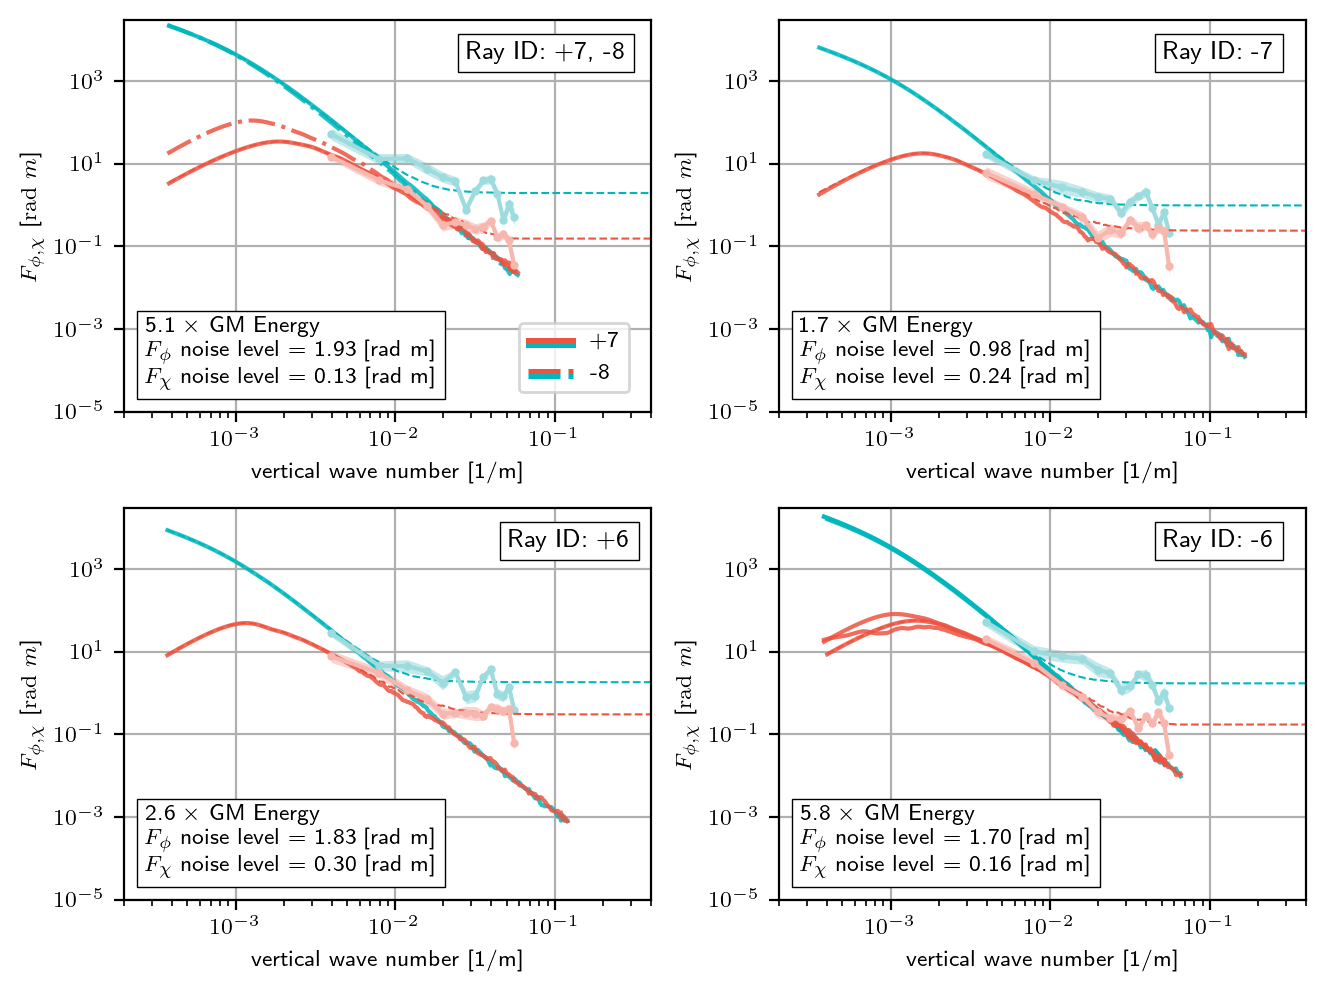

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(6.67, 5))
axes = axes.flatten()

for k, ray_id in enumerate(["+7", "-7", "+6", "-6"]):
    
    F_phis_model, F_chis_model, F_phis_model_nonoise, F_chis_model_nonoise = tools.phi_chi_spectrum_model(m, results[ray_id].x[0], results[ray_id].x[1], results[ray_id].x[2], ray_id, all_paths=True)
    F_phi_model, F_chi_model, F_phi_model_nonoise, F_chi_model_nonoise = F_phis_model[0], F_chis_model[0], F_phis_model_nonoise[0], F_chis_model_nonoise[0]
    
    # compute model spectra for -8 as well (if +7 arrival)
    if ray_id == "+7":
        F_phi_model2, F_chi_model2, F_phi_model_nonoise2, F_chi_model_nonoise2 = tools.phi_chi_spectrum_model(m, results[ray_id].x[0], results[ray_id].x[1], results[ray_id].x[2], '-8')

    # extend noise floor to the right
    nan_mask = np.isnan(F_phi_model)
    F_phi_model = np.hstack((F_phi_model[~nan_mask], F_phi_model[~nan_mask][-1]))
    F_chi_model = np.hstack((F_chi_model[~nan_mask], F_chi_model[~nan_mask][-1]))
    m_extend = np.concatenate((m[:,~nan_mask], np.array([[100]])), axis=1)
    
    plt.sca(axes[k])

    # WFT GMIW F_phi
    for F_phi_model_nonoise in F_phis_model_nonoise:
        plt.plot(m[0] / (2 * np.pi), F_phi_model_nonoise, c=colors[0], lw=1.5, alpha=0.85)
    
    if ray_id == '+7':
        plt.plot(m[0] / (2 * np.pi), F_phi_model_nonoise2, c=colors[0], linestyle='dashdot', lw=1.5, alpha=0.85)
    plt.plot(m_extend[0] / (2 * np.pi), F_phi_model, c=colors[0], lw=0.75, linestyle='dashed')
    
    # F_phi observed
    plt.plot(m_data, F_phi_lm[ray_id], c=colors[1], marker="o", markersize=2)
    plt.fill_between(
        m_data,
        F_phi_lm[ray_id] * F_phi_ls[ray_id],
        F_phi_lm[ray_id] / F_phi_ls[ray_id],
        alpha=0.6,
        color=colors[1],
        lw=0,
    )

    # WFT GMIW F_chi
    
    for F_chi_model_nonoise in F_chis_model_nonoise:
        plt.plot(m[0] / (2 * np.pi), F_chi_model_nonoise, c=colors[2], lw=1.5, alpha=0.85)
    
    if ray_id == '+7':
        plt.plot(m[0] / (2 * np.pi), F_chi_model_nonoise2, c=colors[2], linestyle='dashdot', lw=1.5, alpha=0.85)
    plt.plot(m_extend[0] / (2 * np.pi), F_chi_model, c=colors[2], lw=0.75, linestyle='dashed')
    
    # F_chi observed
    plt.plot(m_data, F_chi_lm[ray_id], c=colors[3], marker="o", markersize=2)
    plt.fill_between(
        m_data,
        F_chi_lm[ray_id] * F_chi_ls[ray_id],
        F_chi_lm[ray_id] / F_chi_ls[ray_id],
        alpha=0.6,
        color=colors[3],
        lw=0,
    )

    # Observational Noise Floor
    #plt.hlines([F_phi_obs_noise[ray_id], F_chi_obs_noise[ray_id]], 1e-2, 1e-0, colors=['C0', 'C2'])
    #print(F_phi_obs_noise[ray_id], F_chi_obs_noise[ray_id])
    
    plt.ylim([1e-5, 3e4])
    plt.xlim([2e-4, 4e-1])

    plt.xlabel("vertical wave number [1/m]")
    plt.ylabel("$F_{\\phi, \\chi}$ [$\\mathrm{rad} \\ m$]")

    plt.yscale("log")
    plt.xscale("log")

    plt.grid()

    if ray_id == '+7':
        plt.text(
            0.65,
            0.9,
            f"Ray ID: {ray_id}, -8",
            transform=axes[k].transAxes,
            fontsize=9,
            bbox=dict(facecolor="white", edgecolor="k", pad=3, linewidth=0.5),
        )

    else:
        plt.text(
            0.73,
            0.9,
            f"Ray ID: {ray_id}",
            transform=axes[k].transAxes,
            fontsize=9,
            bbox=dict(facecolor="white", edgecolor="k", pad=3, linewidth=0.5),
        )
        
    plt.text(
        0.04,
        0.07,
        f"{results[ray_id].x[0]:0.1f} $\\times$ GM Energy\n$F_{{\\phi}}$ noise level = {results[ray_id].x[1]:0.2f} [rad m]\n$F_{{\\chi}}$ noise level = {results[ray_id].x[2]:0.2f} [rad m]",
        transform=axes[k].transAxes,
        fontsize=8,
        bbox=dict(facecolor="white", edgecolor="k", pad=3, linewidth=0.5)
    )

    # add +7,-8 legend
    if ray_id == '+7':
        # Create custom legend handles: for each entry, overlay one Line2D per
        # whoi_color so the legend swatch shows both colors stacked, signaling
        # that the linestyle pattern applies to both.
        solid_lines = tuple(
            mlines.Line2D([], [], color=c, linestyle='-', linewidth=1.8)
            for c in whoi_colors
        )
        dashed_lines = tuple(
            mlines.Line2D([], [], color=c, linestyle='-.', linewidth=1.8)
            for c in whoi_colors
        )

        # Add the custom legend
        axes[k].legend(
            handles=[solid_lines, dashed_lines],
            labels=['+7', '-8'],
            handler_map={tuple: HandlerTupleVertical(ndivide=None, pad=0.1)},
            ncols=1,
            loc=(0.75, 0.05),
        )

plt.tight_layout()

#fig.savefig('../../figures/F_phi_chi_ducted.pdf', bbox_inches='tight')